# 1. Install Libraries

In [ ]:
!pip install numpy
!pip install pandas
!pip install opencv-python
!pip install tensorflow
!pip install scikit-learn
!pip install matplotlib
!pip install torch
!pip install kagglehub

# 2. Imports

In [35]:
#keeping all imports to together for simplicity
import pandas as pd
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from pathlib import Path
from sklearn.model_selection import train_test_split
from google.colab import files
from PIL import Image
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import models
import copy


# 3. Globals

In [18]:
REPO_URL = "https://github.com/Ali-Aryo/LungLens.AI"
DATASET_URL = "paultimothymooney/chest-xray-pneumonia"
SEED = 42
IMG_X = 128
IMG_Y = 128

# X. Helpers

In [19]:
def get_patient_id(filename: str) -> str:
  if "person" in filename:
    return filename.split("_")[0]
  elif "IM" in filename:
    return filename.rsplit("-", 1)[0]
  else:
    raise ValueError(f"Unrecognized filename format: {filename}")


def load_image(rel_path: str) -> np.ndarray:
    """ Image preprocessing
    Load an X-ray as a (IMG_SIZE, IMG_SIZE) grayscale float array in [0, 1]."""
    full_path = DATA_ROOT/rel_path
    img = Image.open(full_path)
    img = img.convert("L") #grey scale image
    img = img.resize((IMG_X, IMG_Y)) #change size
    arr = np.array([])
    arr = np.asarray(img, dtype=np.float32) / 255.0
    return arr






 # 4. Download Dataset


In [20]:
data_path = kagglehub.dataset_download(DATASET_URL)
print("Path to dataset files:", data_path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


# 5. Dataframe

In [21]:
#exmaple path ~chest_xray/data_split/label
DATA_ROOT = Path(data_path) / "chest_xray" # skipping the dup folder - not rly sure why there is a dup


SPLITS = {"train", "val", "test"}
VALID_LABELS = {"NORMAL", "PNEUMONIA"}

table = [] # list of dics
for img_path in sorted(DATA_ROOT.glob("*/*/*.jpeg")):

  if "__MACOSX" in img_path.parts or img_path.name.startswith("._"): #skip non data folders
    continue

  label = img_path.parent.name #normal or pneumonia
  split = img_path.parent.parent.name #train|val|test

  if label not in VALID_LABELS or split not in SPLITS: #skip anything that is not data (prolly not needed)
    continue

  table.append({
      "filepath": str(img_path),
      "filename": img_path.name,
      "label":  label,
      "split":  split,
      "patient_id": get_patient_id(img_path.name)
  })

df = pd.DataFrame(table)

df = df.drop_duplicates(subset=["split", "label", "filename"]).reset_index(drop=True)

#result print statements
assert len(df) == 5856, f"Expected 5856, got {len(df)}"
print(df.groupby(["split", "label"]).size())


split  label    
test   NORMAL        234
       PNEUMONIA     390
train  NORMAL       1341
       PNEUMONIA    3875
val    NORMAL          8
       PNEUMONIA       8
dtype: int64


# 6. Data Split

In [22]:
patients = df.groupby("patient_id")["label"].first().reset_index() #group by patient

train_patients, rest_patients = train_test_split(
    patients,
    test_size=0.3,
    random_state=SEED,
    stratify=patients["label"],
)

val_patients, test_patients = train_test_split(
    rest_patients,
    test_size=0.5,
    random_state=SEED,
    stratify=rest_patients["label"],

)

split_map = {}
for pid in train_patients["patient_id"]:
  split_map[pid] = "train"
for pid in val_patients["patient_id"]:
  split_map[pid] = "val"
for pid in test_patients["patient_id"]:
  split_map[pid] = "test"

df["new_split"] = df["patient_id"].map(split_map)



# 6b. Download splits to CSV

In [23]:
df["filepath"] = df["filepath"].apply(lambda p: Path(p).relative_to(DATA_ROOT).as_posix())

df = df.rename(columns={"split": "orig_split"})

cols = ["filepath", "filename", "label", "patient_id", "orig_split", "new_split"]
df[cols].to_csv("splits.csv", index=False)

#checks
check = pd.read_csv("splits.csv")
print(check.shape)
print(check["filepath"].iloc[0])
check.head()

(5856, 6)
test/NORMAL/IM-0001-0001.jpeg


,filepath,filename,label,patient_id,orig_split,new_split
0,test/NORMAL/IM-0001-0001.jpeg,IM-0001-0001.jpeg,NORMAL,IM-0001,test,train
1,test/NORMAL/IM-0003-0001.jpeg,IM-0003-0001.jpeg,NORMAL,IM-0003,test,test
2,test/NORMAL/IM-0005-0001.jpeg,IM-0005-0001.jpeg,NORMAL,IM-0005,test,train
3,test/NORMAL/IM-0006-0001.jpeg,IM-0006-0001.jpeg,NORMAL,IM-0006,test,train
4,test/NORMAL/IM-0007-0001.jpeg,IM-0007-0001.jpeg,NORMAL,IM-0007,test,val


In [24]:
# files.download("splits.csv") #download the CSV

# 8. KNN baseline

In [25]:
def load_split(split_df: pd.DataFrame):
    """Return X (n_samples, IMG_X*IMG_Y) and y (n_samples,) for one split."""
    X = np.stack([load_image(p).flatten() for p in split_df["filepath"]])
    y = (split_df["label"] == "PNEUMONIA").astype(int).to_numpy() #1 or 0
    return X, y

X_train, y_train = load_split(df[df["new_split"] == "train"])
X_val,   y_val   = load_split(df[df["new_split"] == "val"])
print(X_train.shape, y_train.shape, y_train.mean())
print(X_val.shape, y_val.shape, y_val.mean())

(4127, 16384) (4127,) 0.7310394960019384
(832, 16384) (832,) 0.7199519230769231


# 9. Picking K

k= 1  macro F1=0.888
k= 3  macro F1=0.892
k= 5  macro F1=0.888
k= 7  macro F1=0.890
k=11  macro F1=0.881
k=15  macro F1=0.878
k=21  macro F1=0.877
Best k: 3


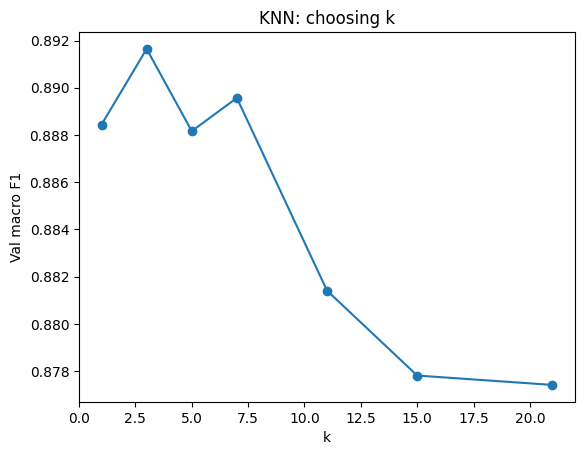

In [26]:
# Try several k values; pick the best by macro F1 on val (fairer than accuracy with ~73% pneumonia)
k_results = {}
for k in [1, 3, 5, 7, 11, 15, 21]:
    knn = KNeighborsClassifier(n_neighbors=k, weights="distance", n_jobs=-1)  # distance weighting = imbalance handling
    knn.fit(X_train, y_train)
    pred = knn.predict(X_val)
    k_results[k] = f1_score(y_val, pred, average="macro")
    print(f"k={k:>2}  macro F1={k_results[k]:.3f}")

best_k = max(k_results, key=k_results.get)
print("Best k:", best_k)

plt.plot(list(k_results.keys()), list(k_results.values()), marker="o")
plt.xlabel("k"); plt.ylabel("Val macro F1"); plt.title("KNN: choosing k"); plt.show()

# 10. KNN Results

              precision    recall  f1-score   support

      NORMAL      0.918     0.773     0.839       233
   PNEUMONIA      0.917     0.973     0.944       599

    accuracy                          0.917       832
   macro avg      0.918     0.873     0.892       832
weighted avg      0.917     0.917     0.915       832



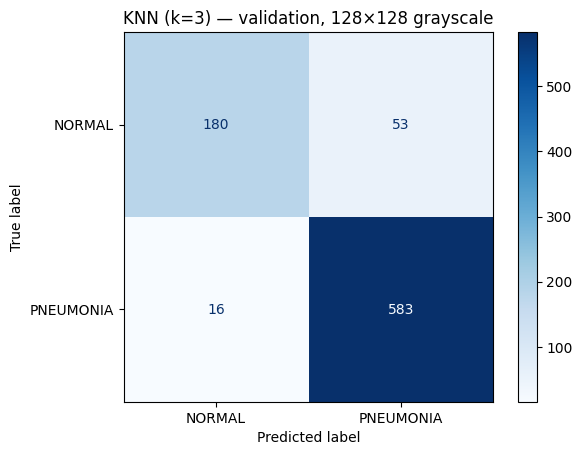

In [27]:
knn = KNeighborsClassifier(n_neighbors=best_k, weights="distance", n_jobs=-1).fit(X_train, y_train)
val_pred = knn.predict(X_val)

print(classification_report(y_val, val_pred, target_names=["NORMAL", "PNEUMONIA"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_val, val_pred),
                       display_labels=["NORMAL", "PNEUMONIA"]).plot(cmap="Blues")
plt.title(f"KNN (k={best_k}) — validation, {IMG_X}×{IMG_Y} grayscale"); plt.show()

# 11. CNN Data Loader

In [28]:
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)                     #

def to_loader(X, y, shuffle):
    """Flat NumPy arrays -> batches of image tensors (N, 1, H, W) for PyTorch."""
    X_t = torch.from_numpy(X).float().reshape(-1, 1, IMG_Y, IMG_X)  # un-flatten back into images
    y_t = torch.from_numpy(y).float()
    return DataLoader(TensorDataset(X_t, y_t), batch_size=32, shuffle=shuffle)

train_loader = to_loader(X_train, y_train, shuffle=True)   # shuffle each epoch while training
val_loader   = to_loader(X_val,   y_val,   shuffle=False)  # fixed order for evaluation

xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape)   # expect torch.Size([32, 1, 128, 128]) torch.Size([32])

Device: cuda
torch.Size([32, 1, 128, 128]) torch.Size([32])


# 12. Load Model

In [30]:
class ResNetXray(nn.Module):
    """Pretrained ResNet-18 adapted to 1-channel X-rays with a single output (pneumonia logit)."""
    def __init__(self):
        super().__init__()
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)  # ImageNet weights
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, 1)            # 1000 classes -> 1 output
        # ImageNet normalization values (registered so they move to the GPU with the model)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):                  # x: (N, 1, 128, 128), values in [0, 1]
        x = x.repeat(1, 3, 1, 1)           # grey -> 3 identical channels, like an RGB photo
        x = (x - self.mean) / self.std     # match the pixel scale ResNet was trained on
        return self.backbone(x).squeeze(1) # (N,) raw scores ("logits")

resnet = ResNetXray().to(device)
out = resnet(xb.to(device))
print(out.shape)   # expect torch.Size([32])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 106MB/s]


torch.Size([32])


# 13. Big Function Cell
# **TODO** Come back to late

In [33]:
def predict(model, loader):
    """Return true labels, 0/1 predictions, and pneumonia probabilities for a loader."""
    model.eval()
    ys, probs = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(torch.sigmoid(model(xb.to(device))).cpu())
            ys.append(yb)
    probs = torch.cat(probs).numpy()
    y_true = torch.cat(ys).numpy().astype(int)
    return y_true, (probs > 0.5).astype(int), probs

def train_model(model, epochs=5, lr=1e-4):
    """Train with class-weighted loss; keep the epoch with the best val macro F1."""
    n_pos = y_train.sum(); n_neg = len(y_train) - n_pos
    # pos_weight < 1 down-weights the majority class (pneumonia), so errors on NORMAL count more
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(n_neg / n_pos, dtype=torch.float32, device=device))
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_state = -1.0, None

    for epoch in range(1, epochs + 1):
        model.train(); total = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)

        model.eval(); vtotal = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                vtotal += loss_fn(model(xb), yb).item() * len(xb)
        y_true, y_pred, _ = predict(model, val_loader)
        f1 = f1_score(y_true, y_pred, average="macro")

        history["train_loss"].append(total / len(train_loader.dataset))
        history["val_loss"].append(vtotal / len(val_loader.dataset))
        history["val_f1"].append(f1)
        print(f"epoch {epoch}: train loss {history['train_loss'][-1]:.4f} | "
              f"val loss {history['val_loss'][-1]:.4f} | val macro F1 {f1:.3f}")
        if f1 > best_f1:
            best_f1, best_state = f1, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    print(f"Best val macro F1: {best_f1:.3f}")
    return history

def plot_history(history, name):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.5))
    a1.plot(history["train_loss"], marker="o", label="train"); a1.plot(history["val_loss"], marker="o", label="val")
    a1.set_title(f"{name}: loss"); a1.set_xlabel("epoch"); a1.legend()
    a2.plot(history["val_f1"], marker="o"); a2.set_title(f"{name}: val macro F1"); a2.set_xlabel("epoch")
    plt.tight_layout(); plt.show()

def evaluate(model, name):
    y_true, y_pred, _ = predict(model, val_loader)
    print(classification_report(y_true, y_pred, target_names=["NORMAL", "PNEUMONIA"], digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                           display_labels=["NORMAL", "PNEUMONIA"]).plot(cmap="Blues")
    plt.title(f"{name} — validation, {IMG_X}×{IMG_Y} grayscale"); plt.show()

# 14. Eval ResNet-18 model (pretrained)

epoch 1: train loss 0.0891 | val loss 0.0611 | val macro F1 0.954
epoch 2: train loss 0.0253 | val loss 0.0592 | val macro F1 0.958
epoch 3: train loss 0.0230 | val loss 0.0744 | val macro F1 0.958
epoch 4: train loss 0.0152 | val loss 0.0644 | val macro F1 0.964
epoch 5: train loss 0.0069 | val loss 0.1001 | val macro F1 0.967
Best val macro F1: 0.967


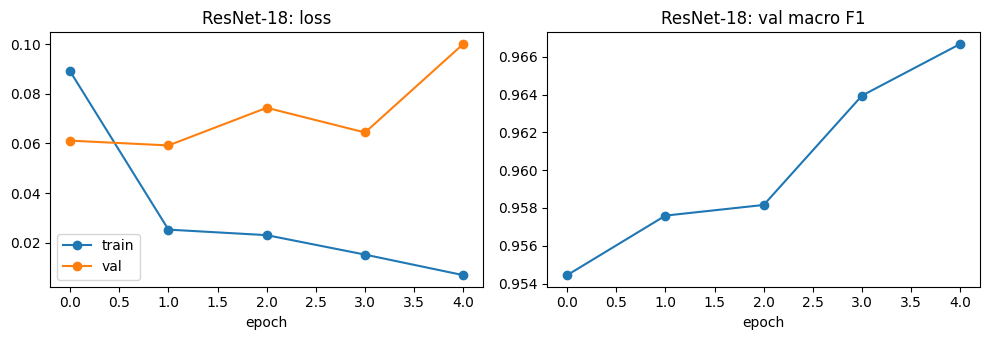

              precision    recall  f1-score   support

      NORMAL      0.977     0.927     0.952       233
   PNEUMONIA      0.972     0.992     0.982       599

    accuracy                          0.974       832
   macro avg      0.975     0.959     0.967       832
weighted avg      0.974     0.974     0.973       832



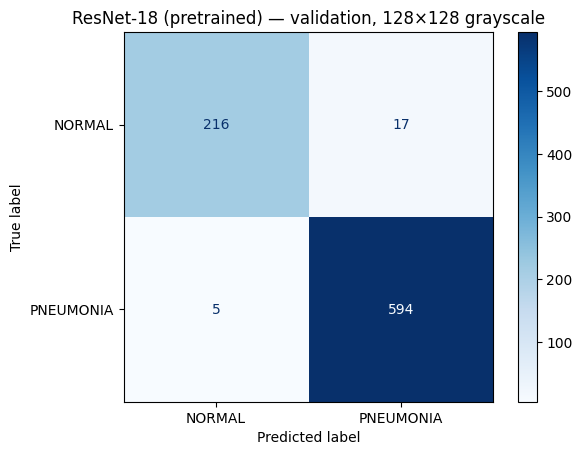

In [36]:
resnet = ResNetXray().to(device)
resnet_hist = train_model(resnet, epochs=5, lr=1e-4)
plot_history(resnet_hist, "ResNet-18")
evaluate(resnet, "ResNet-18 (pretrained)")

# 15. Train CNN **TODO** Come back to

Scratch CNN params: 97761
ResNet-18 params:   11177025
epoch 1: train loss 0.1787 | val loss 0.1968 | val macro F1 0.788
epoch 2: train loss 0.1316 | val loss 0.1620 | val macro F1 0.823
epoch 3: train loss 0.1098 | val loss 0.1539 | val macro F1 0.913
epoch 4: train loss 0.0959 | val loss 0.1306 | val macro F1 0.878
epoch 5: train loss 0.0845 | val loss 0.1085 | val macro F1 0.911
epoch 6: train loss 0.0798 | val loss 0.1795 | val macro F1 0.802
epoch 7: train loss 0.0855 | val loss 0.1062 | val macro F1 0.914
epoch 8: train loss 0.0808 | val loss 0.1393 | val macro F1 0.930
epoch 9: train loss 0.0687 | val loss 0.0919 | val macro F1 0.928
epoch 10: train loss 0.0697 | val loss 0.1039 | val macro F1 0.919
Best val macro F1: 0.930


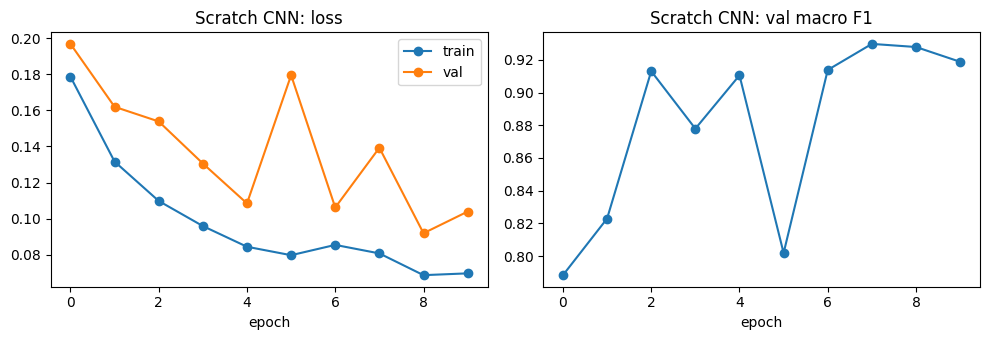

              precision    recall  f1-score   support

      NORMAL      0.970     0.833     0.896       233
   PNEUMONIA      0.938     0.990     0.963       599

    accuracy                          0.946       832
   macro avg      0.954     0.911     0.930       832
weighted avg      0.947     0.946     0.945       832



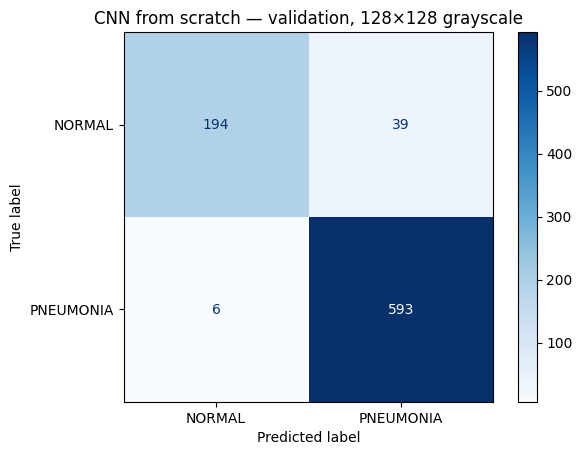

In [37]:
class SmallCNN(nn.Module):
    """CNN from scratch: 4 conv blocks (conv → batchnorm → ReLU → maxpool), then a small classifier."""
    def __init__(self):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out),
                                 nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), block(64, 128))  # 128→64→32→16→8 px
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                        nn.Dropout(0.3), nn.Linear(128, 1))

    def forward(self, x):                  # x: (N, 1, 128, 128) in [0, 1]
        x = (x - 0.5) / 0.5                # center pixels around 0
        return self.classifier(self.features(x)).squeeze(1)

torch.manual_seed(SEED)
cnn = SmallCNN().to(device)
print("Scratch CNN params:", sum(p.numel() for p in cnn.parameters()))
print("ResNet-18 params:  ", sum(p.numel() for p in resnet.parameters()))
cnn_hist = train_model(cnn, epochs=10, lr=1e-3)   # from scratch: more epochs, higher learning rate
plot_history(cnn_hist, "Scratch CNN")
evaluate(cnn, "CNN from scratch")

# 16. Compare CNN to ResNet-18

,Model,Accuracy,Normal recall,Pneumonia recall,Macro F1
0,KNN (k=3),0.917,0.773,0.973,0.892
1,ResNet-18 (pretrained),0.974,0.927,0.992,0.967
2,CNN from scratch,0.946,0.833,0.990,0.930


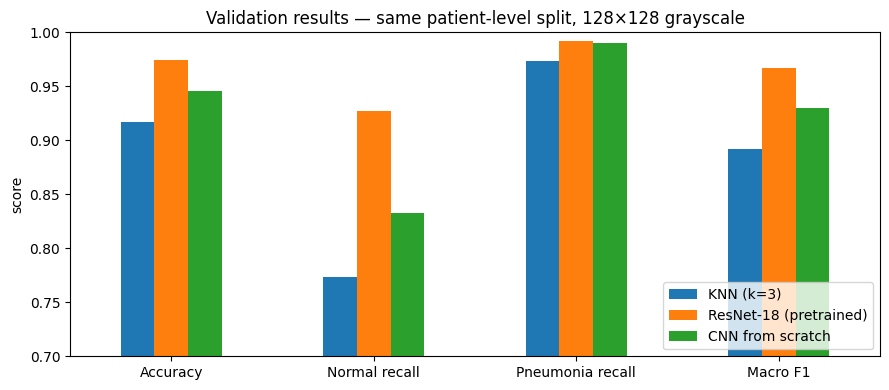

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
from sklearn.metrics import accuracy_score, recall_score

# KNN predictions (refit is fast: k=3 chosen earlier)
knn = KNeighborsClassifier(n_neighbors=3, weights="distance", n_jobs=-1).fit(X_train, y_train)

preds = {
    "KNN (k=3)":              (y_val, knn.predict(X_val)),
    "ResNet-18 (pretrained)": predict(resnet, val_loader)[:2],
    "CNN from scratch":       predict(cnn, val_loader)[:2],
}

rows = []
for name, (yt, yp) in preds.items():
    rows.append({
        "Model": name,
        "Accuracy":         accuracy_score(yt, yp),
        "Normal recall":    recall_score(yt, yp, pos_label=0),
        "Pneumonia recall": recall_score(yt, yp, pos_label=1),
        "Macro F1":         f1_score(yt, yp, average="macro"),
    })
results = pd.DataFrame(rows).round(3)
display(results)

# Grouped bar chart for the report
results.set_index("Model")[["Accuracy", "Normal recall", "Pneumonia recall", "Macro F1"]].T.plot(
    kind="bar", figsize=(9, 4), ylim=(0.7, 1.0), rot=0)
plt.title(f"Validation results — same patient-level split, {IMG_X}×{IMG_Y} grayscale")
plt.ylabel("score"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

# Save results + trained weights so M2 doesn't need retraining
results.to_csv("m1_results.csv", index=False)
torch.save(resnet.state_dict(), "resnet18_m1.pt")
torch.save(cnn.state_dict(), "scratch_cnn_m1.pt")
for f in ["m1_results.csv", "resnet18_m1.pt", "scratch_cnn_m1.pt"]:
    files.download(f)